# Apprentissage d'ensemble : vote hard et vote soft

**Objectif** : combiner les trois modèles déjà entraînés (KNN, SVM, Random Forest) et voir si le vote fait mieux que le meilleur d'entre eux.

| Vote | Règle |
|---|---|
| **Hard** | chaque modèle vote pour une classe, la majorité l'emporte. En cas d'égalité 1-1-1, on suit le modèle qui a le meilleur macro-F1 de validation |
| **Soft** | on fait la moyenne des probabilités des trois modèles, puis on prend la classe de plus forte probabilité |

**Protocole**
- Les trois modèles sont rechargés depuis `results/models/` (même configuration, mêmes données d'entraînement). Aucun ne est ré-entraîné, sauf le SVM : le vote soft a besoin de probabilités, donc on entraîne une version `probability=True` avec **les mêmes hyperparamètres et les mêmes lignes**, enregistrée à part dans `results/models_ensemble/`.
- Poids égaux, non réglés sur le test. Le test n'est utilisé que pour mesurer.
- Les prédictions sont mises en cache : relancer la section 5 ne recalcule pas KNN et SVM (les plus lents).

In [ ]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from datetime import datetime

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Dossiers (les mêmes que dans 05_Supervised_Learning)
BASE = os.environ.get("DM_BASE", r"C:\Users\chahi\Desktop\DM-Weather-framework\data")
# BASE = os.environ.get("DM_BASE", r"D:\M2\Data Mining\DM-Weather-framework\data")
SUP_DIR = os.path.join(BASE, "processed", "transformed", "supervised")
RES_DIR = r"C:\Users\chahi\Desktop\DM-Weather-framework\results"
TABLES_DIR = os.path.join(RES_DIR, "tables")
FIGURES_DIR = os.path.join(RES_DIR, "figures")
MODELES_DIR = os.path.join(RES_DIR, "supervised_models")
ENS_DIR = os.path.join(RES_DIR, "models_ensemble")      # les fichiers de l'ensemble sont rangés à part
for d in (TABLES_DIR, FIGURES_DIR, ENS_DIR):
    os.makedirs(d, exist_ok=True)

LABELS = ["Low", "Medium", "High"]
SEED = 42

# ---- Paramètres de l'expérience ----
CONFIG = "reduit_sans_year"      # configuration des trois modèles : complet, complet_sans_year, reduit, reduit_sans_year
DONNEES = "train_complet"        # "echantillon" ou "train_complet"
RECALCULER = False               # True = refait l'entraînement du SVM avec probabilités et les prédictions

In [2]:
train  = pd.read_parquet(os.path.join(SUP_DIR, "train_supervised.parquet"))
test   = pd.read_parquet(os.path.join(SUP_DIR, "test_supervised.parquet"))
sample = pd.read_parquet(os.path.join(SUP_DIR, "train_sample_30k.parquet"))

for d in (train, test, sample):
    d["classe"] = d["classe"].astype(str)
    d["date"] = pd.to_datetime(d["date"])
sample = sample.reset_index(drop=True)
print("Train :", train.shape, "| Test :", test.shape, "| Échantillon :", sample.shape)

Train : (602175, 18) | Test : (151900, 18) | Échantillon : (30000, 18)


In [3]:
resultats = []   # une ligne par modèle

def noter(nom, y_vrai, y_pred, temps_fit=None, temps_pred=None):
    ligne = {"modele": nom,
             "accuracy": accuracy_score(y_vrai, y_pred),
             "macro_F1": f1_score(y_vrai, y_pred, labels=LABELS, average="macro")}
    for classe in LABELS:
        ligne["F1_" + classe] = f1_score(y_vrai, y_pred, labels=[classe], average=None)[0]
    ligne["temps_fit_s"] = temps_fit
    ligne["temps_pred_s"] = temps_pred
    resultats.append(ligne)

y_test = test["classe"].to_numpy()

# Les deux baselines de 05 (calculées sur le train)
pred_majoritaire = np.full(len(y_test), train["classe"].mode()[0])
majoritaire_par_mois = train.groupby("month")["classe"].agg(lambda s: s.mode()[0])
pred_par_mois = test["month"].map(majoritaire_par_mois).to_numpy()

## 1. Les trois modèles de base

In [4]:
NOMS = ["knn", "svm", "rf"]
dossier_cfg = os.path.join(MODELES_DIR, CONFIG)

MEMBRES = {}
for nom in NOMS:
    base = os.path.join(dossier_cfg, nom + "_" + DONNEES)
    if not os.path.exists(base + ".pkl"):
        raise FileNotFoundError("Modèle introuvable : " + base + ".pkl  (lance d'abord la section 5 de 05_Supervised_Learning)")
    with open(base + ".json", encoding="utf-8") as f:
        MEMBRES[nom] = {"modele": joblib.load(base + ".pkl"), "fiche": json.load(f)}

variables = MEMBRES["knn"]["fiche"]["variables"]
assert all(m["fiche"]["variables"] == variables for m in MEMBRES.values()), "Les 3 modèles n'ont pas les mêmes variables"

# En cas d'égalité 1-1-1 au vote hard, on suit le modèle au meilleur macro-F1 de validation
def score_val(n):
    v = MEMBRES[n]["fiche"].get("macro_F1_validation")
    return -1 if v is None else v
MEILLEUR_MEMBRE = max(NOMS, key=score_val)

resume = pd.DataFrame([{"modele": n, "n_lignes": m["fiche"]["n_lignes"], "parametres": m["fiche"]["parametres"],
                        "macro_F1_validation": m["fiche"].get("macro_F1_validation")} for n, m in MEMBRES.items()])
display(resume)
print("Configuration :", CONFIG, "|", len(variables), "variables | départage des égalités :", MEILLEUR_MEMBRE)

,modele,n_lignes,parametres,macro_F1_validation
0,knn,602175,"{'n_neighbors': 15, 'weights': 'distance', 'al...",0.841003
1,svm,100000,"{'C': 10, 'gamma': 'scale'}",0.864438
2,rf,602175,"{'max_depth': 25, 'min_samples_leaf': 5, 'n_es...",0.869833


Configuration : reduit_sans_year | 11 variables | départage des égalités : rf


## 2. SVM avec probabilités

Le SVM enregistré a été entraîné avec `probability=False`. On entraîne ici le même modèle (mêmes hyperparamètres, mêmes lignes d'entraînement) avec `probability=True` : scikit-learn ajoute alors une validation croisée interne à 5 plis pour calibrer les probabilités, donc l'ajustement est environ 5 fois plus long. Le fichier obtenu est enregistré dans `results/models_ensemble/` et réutilisé aux exécutions suivantes.

Les étiquettes prédites (`predict`) viennent toujours de l'hyperplan du SVM, pas des probabilités ; on vérifie plus bas qu'elles sont identiques à celles du SVM enregistré.

In [5]:
def svm_avec_probabilites():
    dossier = os.path.join(ENS_DIR, CONFIG)
    os.makedirs(dossier, exist_ok=True)
    chemin = os.path.join(dossier, "svm_proba_" + DONNEES + ".pkl")
    if os.path.exists(chemin) and not RECALCULER:
        print("SVM avec probabilités rechargé :", chemin)
        return joblib.load(chemin)

    fiche = MEMBRES["svm"]["fiche"]
    params = dict(fiche["hyperparametres_complets"])
    params["probability"] = True
    modele = SVC(**params)

    # Mêmes lignes que le SVM enregistré (même graine, même nombre de lignes)
    if DONNEES == "echantillon":
        X = sample
    else:
        X = train if fiche["n_lignes"] >= len(train) else train.sample(fiche["n_lignes"], random_state=SEED)
    print("Entraînement du SVM avec probabilités sur", len(X), "lignes ...")
    t0 = time.time()
    modele.fit(X[variables], X["classe"].to_numpy())
    duree = time.time() - t0

    joblib.dump(modele, chemin)
    with open(chemin.replace(".pkl", ".json"), "w", encoding="utf-8") as f:
        json.dump({"nom": "svm_proba_" + DONNEES, "config": CONFIG, "donnees": DONNEES, "variables": variables,
                   "n_lignes": int(len(X)), "hyperparametres_complets": modele.get_params(),
                   "temps_fit_s": round(duree, 1), "date_entrainement": datetime.now().strftime("%Y-%m-%d %H:%M"),
                   "version_sklearn": sklearn.__version__}, f, indent=2, default=str)
    print("Enregistré :", chemin, "(", round(duree, 1), "s )")
    return modele

SVM_PROBA = svm_avec_probabilites()

# Vérification : mêmes étiquettes que le SVM enregistré (sur 3 000 lignes du test)
Xv = test[variables].iloc[:3000]
accord = (MEMBRES["svm"]["modele"].predict(Xv) == SVM_PROBA.predict(Xv)).mean()
print("Accord entre le SVM enregistré et le SVM avec probabilités :", round(accord * 100, 2), "%")

Entraînement du SVM avec probabilités sur 100000 lignes ...


c:\Users\chahi\Desktop\DM-Weather-framework\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Enregistré : C:\Users\chahi\Desktop\DM-Weather-framework\results\models_ensemble\reduit_sans_year\svm_proba_train_complet.pkl ( 615.8 s )
Accord entre le SVM enregistré et le SVM avec probabilités : 100.0 %


## 3. Prédictions sur le test

Pour chaque modèle : les probabilités (colonnes dans l'ordre Low, Medium, High) et la classe prédite. Pour KNN et Random Forest, la classe est celle de plus forte probabilité, ce qui est exactement ce que fait `predict`. Pour le SVM, on appelle `predict`.

Cette cellule est la plus longue (KNN et SVM sur le test complet). Le résultat est mis en cache ; `RECALCULER = True` pour le refaire.

In [6]:
Xtest = test[variables]
CACHE = os.path.join(ENS_DIR, CONFIG, "predictions_test_" + DONNEES + ".npz")

if os.path.exists(CACHE) and not RECALCULER:
    c = np.load(CACHE)
    proba = {n: c["proba_" + n] for n in NOMS}
    pred = {n: c["pred_" + n] for n in NOMS}
    temps_pred = {n: float(c["temps_" + n]) for n in NOMS}
    print("Prédictions rechargées :", CACHE)
else:
    modeles = {"knn": MEMBRES["knn"]["modele"], "svm": SVM_PROBA, "rf": MEMBRES["rf"]["modele"]}
    proba, pred, temps_pred = {}, {}, {}
    for n in NOMS:
        t0 = time.time()
        p = modeles[n].predict_proba(Xtest)
        classes = list(modeles[n].classes_)
        proba[n] = pd.DataFrame(p, columns=classes).reindex(columns=LABELS).to_numpy()     # ordre Low, Medium, High
        pred[n] = modeles[n].predict(Xtest) if n == "svm" else np.array(classes)[p.argmax(axis=1)]
        pred[n] = np.asarray(pred[n], dtype=str)
        temps_pred[n] = round(time.time() - t0, 1)
        print(n, ": prédit en", temps_pred[n], "s")
    np.savez(CACHE, **{"proba_" + n: proba[n] for n in NOMS}, **{"pred_" + n: pred[n] for n in NOMS},
             **{"temps_" + n: temps_pred[n] for n in NOMS})
    print("Prédictions enregistrées :", CACHE)

knn : prédit en 190.0 s
svm : prédit en 454.5 s
rf : prédit en 0.7 s
Prédictions enregistrées : C:\Users\chahi\Desktop\DM-Weather-framework\results\models_ensemble\reduit_sans_year\predictions_test_train_complet.npz


## 4. Les deux votes

In [7]:
POIDS = {"knn": 1, "svm": 1, "rf": 1}      # poids égaux : on ne règle rien sur le test
w = np.array([POIDS[n] for n in NOMS], dtype=float)
index = {c: i for i, c in enumerate(LABELS)}

# Vote soft : moyenne des probabilités, puis classe de plus forte probabilité
P = np.stack([proba[n] for n in NOMS])                      # (modèles, lignes, classes)
proba_moyenne = np.tensordot(w / w.sum(), P, axes=1)        # (lignes, classes)
pred_soft = np.array(LABELS)[proba_moyenne.argmax(axis=1)]

# Vote hard : la classe qui a le plus de voix (pondérées)
V = np.stack([pd.Series(pred[n]).map(index).to_numpy() for n in NOMS])     # (modèles, lignes)
comptes = np.stack([((V == k) * w[:, None]).sum(axis=0) for k in range(len(LABELS))], axis=1)
egalite = (comptes == comptes.max(axis=1, keepdims=True)).sum(axis=1) > 1   # plusieurs classes à égalité
vote = comptes.argmax(axis=1)
vote[egalite] = V[NOMS.index(MEILLEUR_MEMBRE)][egalite]                    # départage : meilleur modèle en validation
pred_hard = np.array(LABELS)[vote]

print("Égalités au vote hard :", int(egalite.sum()), "lignes sur", len(egalite),
      "(", round(egalite.mean() * 100, 2), "% ), départagées par", MEILLEUR_MEMBRE)

Égalités au vote hard : 37 lignes sur 151900 ( 0.02 % ), départagées par rf


## 5. Résultats sur le test

In [8]:
resultats = []
noter("Baseline : classe majoritaire", y_test, pred_majoritaire)
noter("Baseline : classe majoritaire par mois", y_test, pred_par_mois)
for n in NOMS:
    noter(n.upper() + " | " + DONNEES, y_test, pred[n], MEMBRES[n]["fiche"].get("temps_fit_s"), temps_pred[n])
noter("Vote hard", y_test, pred_hard)
noter("Vote soft", y_test, pred_soft)

tableau = pd.DataFrame(resultats).round(4)
display(tableau)

meilleur_seul = tableau[tableau["modele"].str.contains(r"\| " + DONNEES)]["macro_F1"].max()
for nom in ("Vote hard", "Vote soft"):
    mf = tableau.loc[tableau["modele"] == nom, "macro_F1"].iloc[0]
    print(f"{nom} : macro-F1 {mf:.4f}  ({mf - meilleur_seul:+.4f} par rapport au meilleur modèle seul)")

dossier_test = os.path.join(TABLES_DIR, "test")
os.makedirs(dossier_test, exist_ok=True)
chemin_csv = os.path.join(dossier_test, "resultats_ensemble_" + CONFIG + "_" + DONNEES + ".csv")
tableau.to_csv(chemin_csv, index=False)
print("Tableau enregistré :", chemin_csv)

,modele,accuracy,macro_F1,F1_Low,F1_Medium,F1_High,temps_fit_s,temps_pred_s
0,Baseline : classe majoritaire,0.3892,0.1868,0.0000,0.5603,0.0000,NaN,NaN
1,Baseline : classe majoritaire par mois,0.8081,0.7728,0.6824,0.7428,0.8933,NaN,NaN
2,KNN | train_complet,0.8896,0.8653,0.7938,0.8611,0.9410,1.2,190.0
3,SVM | train_complet,0.8993,0.8834,0.8395,0.8662,0.9445,90.8,454.5
4,RF | train_complet,0.8890,0.8693,0.8105,0.8604,0.9369,111.4,0.7
5,Vote hard,0.8992,0.8807,0.8267,0.8712,0.9443,NaN,NaN
6,Vote soft,0.9010,0.8828,0.8300,0.8753,0.9432,NaN,NaN


Vote hard : macro-F1 0.8807  (-0.0027 par rapport au meilleur modèle seul)
Vote soft : macro-F1 0.8828  (-0.0006 par rapport au meilleur modèle seul)
Tableau enregistré : C:\Users\chahi\Desktop\DM-Weather-framework\results\tables\test\resultats_ensemble_reduit_sans_year_train_complet.csv


In [9]:
for nom, y_pred in (("Vote hard", pred_hard), ("Vote soft", pred_soft)):
    print("=====", nom)
    print(classification_report(y_test, y_pred, labels=LABELS, digits=3))

===== Vote hard
              precision    recall  f1-score   support

         Low      0.786     0.872     0.827     20169
      Medium      0.867     0.876     0.871     59113
        High      0.963     0.926     0.944     72618

    accuracy                          0.899    151900
   macro avg      0.872     0.891     0.881    151900
weighted avg      0.902     0.899     0.900    151900

===== Vote soft
              precision    recall  f1-score   support

         Low      0.816     0.844     0.830     20169
      Medium      0.858     0.893     0.875     59113
        High      0.964     0.923     0.943     72618

    accuracy                          0.901    151900
   macro avg      0.880     0.887     0.883    151900
weighted avg      0.903     0.901     0.902    151900



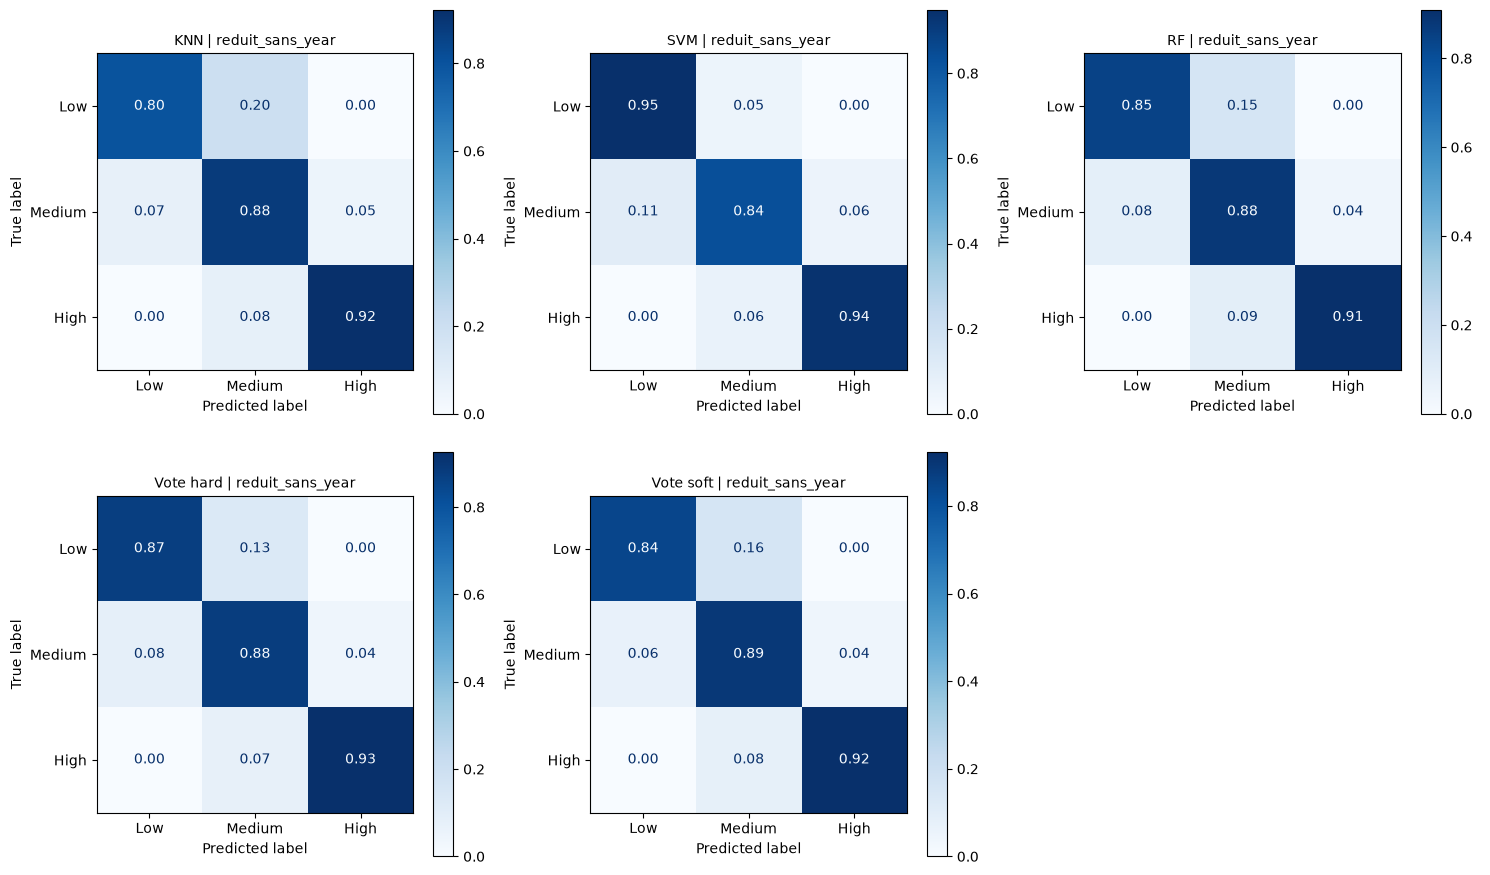

Figure enregistrée : C:\Users\chahi\Desktop\DM-Weather-framework\results\figures\matrices_confusion_ensemble_reduit_sans_year_train_complet.png


In [10]:
panneaux = [(n.upper(), pred[n]) for n in NOMS] + [("Vote hard", pred_hard), ("Vote soft", pred_soft)]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
axes[-1].axis("off")
for ax, (titre, y_pred) in zip(axes, panneaux):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=LABELS, normalize="true",
                                            ax=ax, cmap="Blues", values_format=".2f")
    ax.set_title(titre + " | " + CONFIG, fontsize=10)
plt.tight_layout()
chemin_fig = os.path.join(FIGURES_DIR, "matrices_confusion_ensemble_" + CONFIG + "_" + DONNEES + ".png")
plt.savefig(chemin_fig, dpi=150)
plt.show()
print("Figure enregistrée :", chemin_fig)

## 6. Diversité des modèles

Un vote n'aide que si les modèles ne se trompent pas tous aux mêmes endroits. On mesure :
- le **désaccord** entre chaque paire de modèles (part des lignes où leurs prédictions diffèrent) ;
- la part des lignes où **les trois ont raison**, où **au moins un a raison** (plafond théorique d'un vote parfait) et où **aucun n'a raison** (le vote ne peut rien y faire).

In [11]:
paires = [("knn", "svm"), ("knn", "rf"), ("svm", "rf")]
desaccord = pd.DataFrame([{"paire": a.upper() + " / " + b.upper(),
                           "desaccord_%": round((pred[a] != pred[b]).mean() * 100, 2)} for a, b in paires])
display(desaccord)

justes = np.stack([pred[n] == y_test for n in NOMS])
couverture = pd.DataFrame({
    "tous_les_3_justes_%":  [round(justes.all(axis=0).mean() * 100, 2)],
    "au_moins_un_juste_%":  [round(justes.any(axis=0).mean() * 100, 2)],
    "aucun_juste_%":        [round((~justes).all(axis=0).mean() * 100, 2)],
    "accuracy_vote_hard_%": [round((pred_hard == y_test).mean() * 100, 2)],
    "accuracy_vote_soft_%": [round((pred_soft == y_test).mean() * 100, 2)],
})
display(couverture)

,paire,desaccord_%
0,KNN / SVM,8.09
1,KNN / RF,6.21
2,SVM / RF,6.22


,tous_les_3_justes_%,au_moins_un_juste_%,aucun_juste_%,accuracy_vote_hard_%,accuracy_vote_soft_%
0,83.82,94.07,5.93,89.92,90.1


## 7. Enregistrement de l'ensemble

In [12]:
recette = {
    "nom": "voting_" + DONNEES,
    "config": CONFIG,
    "donnees": DONNEES,
    "variables": variables,
    "classes": LABELS,
    "membres": {
        "knn": os.path.join(MODELES_DIR, CONFIG, "knn_" + DONNEES + ".pkl"),
        "svm_hard": os.path.join(MODELES_DIR, CONFIG, "svm_" + DONNEES + ".pkl"),
        "svm_soft": os.path.join(ENS_DIR, CONFIG, "svm_proba_" + DONNEES + ".pkl"),
        "rf": os.path.join(MODELES_DIR, CONFIG, "rf_" + DONNEES + ".pkl"),
    },
    "vote_hard": {"poids": POIDS, "regle": "classe avec le plus de voix",
                  "departage": "prédiction du modèle " + MEILLEUR_MEMBRE + " (meilleur macro-F1 de validation)"},
    "vote_soft": {"poids": POIDS, "regle": "moyenne des probabilités, puis classe de plus forte probabilité"},
    "date": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "version_sklearn": sklearn.__version__,
}
dossier = os.path.join(ENS_DIR, CONFIG)
os.makedirs(dossier, exist_ok=True)
chemin = os.path.join(dossier, "voting_" + DONNEES + ".json")
with open(chemin, "w", encoding="utf-8") as f:
    json.dump(recette, f, indent=2, ensure_ascii=False)
print("Recette de l'ensemble enregistrée :", chemin)

Recette de l'ensemble enregistrée : C:\Users\chahi\Desktop\DM-Weather-framework\results\models_ensemble\reduit_sans_year\voting_train_complet.json
